# AI Reorder Point & Inventory Management — EDA, Model Selection & Verification

**Exercise:** Session II — AI Applications in Reorder Point & Inventory Management
**Industry:** FMCG / grocery retail (non-perishable) · **Data:** Kaggle *Store Sales – Time Series Forecasting* (Corporación Favorita, Ecuador)

This notebook is the offline companion to the dashboard. It documents every data decision, verifies the
calculations independently of the TypeScript code, and exports **golden values** that the dashboard's unit tests must reproduce.

| Part | Sections | Status |
|---|---|---|
| A | 1 Data audit · 2 Cleaning rules · 3 EDA · 4 Series shortlist · 5 Safety-stock hand calculation & Monte Carlo cross-check · 6 Demo-generator validation · 7 Golden values | done |
| B | 8 Forecast model selection & comparison (browser ETS/Ridge/LSTM/ensemble vs SARIMAX, LightGBM, Keras LSTM) | done |
| C | 9 Dynamic safety stock (baseline vs AI) and Monte Carlo, with an independent NumPy re-implementation | done |
| D | 10 Bayesian optimisation under constraints vs exhaustive grid, with an independent NumPy policy simulator | this version |

> **Data use:** the Kaggle data is used under the competition rules for non-commercial academic education. Only aggregate
> statistics and charts are shown here; raw rows are not printed, and the raw Kaggle CSVs are never committed.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
import favorita_data as fd

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
CYAN, AMBER, GREEN, RED, VIOLET, SLATE = "#0891B2", "#D97706", "#059669", "#E11D48", "#7C3AED", "#475569"
pd.set_option("display.width", 160)

raw = fd.load_raw()          # full data for the audit
print(f"train {raw.train.shape}, test {raw.test.shape}, oil {raw.oil.shape}, holidays {raw.holidays.shape}, stores {raw.stores.shape}")

train (3000888, 5), test (28512, 4), oil (1218, 2), holidays (350, 6), stores (54, 5)


## 1 · Data audit

In [2]:
tr = raw.train
dates = pd.DatetimeIndex(tr.date.unique())
full = pd.date_range(dates.min(), dates.max())
audit = {
    "date range": f"{dates.min().date()} → {dates.max().date()}",
    "unique dates / calendar days": f"{len(dates)} / {len(full)}",
    "missing calendar dates": ", ".join(str(d.date()) for d in full.difference(dates)),
    "stores × families": f"{tr.store_nbr.nunique()} × {tr.family.nunique()} = {tr.groupby(['store_nbr','family'], observed=True).ngroups} series",
    "rows per date (unique values)": str(tr.groupby('date').size().unique().tolist()),
    "null values": int(tr.isna().sum().sum()),
    "duplicate (date, store, family)": int(tr.duplicated(['date','store_nbr','family']).sum()),
    "negative sales": int((tr.sales < 0).sum()),
    "share of zero-sales rows": f"{(tr.sales == 0).mean():.1%}",
    "share of fractional sales rows": f"{((tr.sales % 1) != 0).mean():.1%}",
    "first date with any promotion": str(tr.loc[tr.onpromotion > 0, 'date'].min().date()),
    "oil: null prices / calendar days without a price": f"{raw.oil.dcoilwtico.isna().sum()} / {len(pd.date_range(raw.oil.date.min(), raw.oil.date.max()).difference(raw.oil.date))}",
    "holidays: transferred rows / duplicate dates": f"{raw.holidays.transferred.sum()} / {raw.holidays.date.duplicated().sum()}",
    "test.csv (planned promotions) range": f"{raw.test.date.min().date()} → {raw.test.date.max().date()}",
}
pd.Series(audit, name="value").to_frame()

,value
date range,2013-01-01 → 2017-08-15
unique dates / calendar days,1684 / 1688
missing calendar dates,"2013-12-25, 2014-12-25, 2015-12-25, 2016-12-25"
stores × families,54 × 33 = 1782 series
rows per date (unique values),[1782]
null values,0
"duplicate (date, store, family)",0
negative sales,0
share of zero-sales rows,31.3%
share of fractional sales rows,15.4%


In [3]:
# Store openings and long closures (store-level total sales == 0)
sd = tr.groupby(["store_nbr", "date"], observed=True).sales.sum().reset_index()
first_sale = sd[sd.sales > 0].groupby("store_nbr").date.min()
def longest_zero_run(g):
    z = (g.sort_values("date").sales.to_numpy() == 0).astype(int)
    best = cur = 0
    for v in z:
        cur = cur + 1 if v else 0; best = max(best, cur)
    return best
runs = sd[sd.date >= sd.store_nbr.map(first_sale)].groupby("store_nbr").apply(longest_zero_run, include_groups=False)
late = first_sale[first_sale > "2013-01-02"].dt.date
print("Stores opening after 2013-01-02:", late.to_dict())
print("Stores with ≥7 consecutive zero-sales days after opening:", runs[runs >= 7].to_dict())

Stores opening after 2013-01-02: {20: datetime.date(2015, 2, 13), 21: datetime.date(2015, 7, 24), 22: datetime.date(2015, 10, 9), 29: datetime.date(2015, 3, 20), 36: datetime.date(2013, 5, 9), 42: datetime.date(2015, 8, 21), 52: datetime.date(2017, 4, 20), 53: datetime.date(2014, 5, 29)}
Stores with ≥7 consecutive zero-sales days after opening: {12: 60, 14: 38, 18: 110, 24: 101, 25: 66, 30: 23}


In [4]:
fam = (tr.groupby("family", observed=True)
         .agg(total_units=("sales", "sum"), zero_share=("sales", lambda x: (x == 0).mean()),
              fractional_share=("sales", lambda x: ((x % 1) != 0).mean()), mean_promo=("onpromotion", "mean"))
         .sort_values("total_units", ascending=False))
fam.style.format({"total_units": "{:,.0f}", "zero_share": "{:.1%}", "fractional_share": "{:.1%}", "mean_promo": "{:.2f}"})

,total_units,zero_share,fractional_share,mean_promo
family,,,,
GROCERY I,"343,462,735",8.1%,15.1%,21.06
BEVERAGES,"216,954,486",8.1%,0.0%,9.97
PRODUCE,"122,704,685",28.4%,57.5%,12.29
CLEANING,"97,521,289",8.1%,0.0%,7.27
DAIRY,"64,487,709",8.1%,0.0%,8.01
BREAD/BAKERY,"42,133,946",8.1%,43.4%,3.64
POULTRY,"31,876,004",8.1%,91.8%,2.49
MEATS,"31,086,468",8.1%,91.8%,3.34
PERSONAL CARE,"24,592,051",8.1%,0.0%,2.72


## 2 · Cleaning rules (implemented once in `scripts/favorita_data.py`)

| # | Rule | Why |
|---|---|---|
| 1 | Insert 25 Dec rows and flag every zero-total-sales store-day as `closed` | Stores are closed; closed days are excluded from model training, D̄/σ_D and accuracy metrics; demand = 0 in simulation |
| 2 | Model window starts **2014-04-01** | Promotions are only recorded from that date (earlier zeros = *missing*); also avoids the 2013 level shift |
| 3 | Oil: daily calendar + linear interpolation, used as a 7-day lagged mean | 43 null prices and non-trading days; lag avoids same-day information |
| 4 | Holidays: drop `transferred=True`; Holiday/Additional/Bridge/Transfer → holiday; Work Day → work day; Event → event (earthquake separately); National → all stores, Regional → state, Local → city | Kaggle data notes |
| 5 | Paydays (15th & month-end), pre-Christmas ramp | Kaggle data notes; strong December build-up |
| 6 | Future promotions for 2017-08-16..31 from `test.csv` | They are planned in advance, so they are legitimate forecast inputs |
| 7 | `transactions.csv` not used as a forecast input | Only known after the day ends (leakage) |

Store 44: Quito, Pichincha, type A, cluster 5
Calendar flag-days 2013-01-01..2017-08-31: {'holiday': 90, 'event': 25, 'quake': 31, 'work_day': 5} | closed days: 9 → ['2013-01-01', '2013-12-25', '2014-01-01', '2014-12-25', '2015-01-01', '2015-12-25', '2016-01-01', '2016-12-25', '2017-01-01']


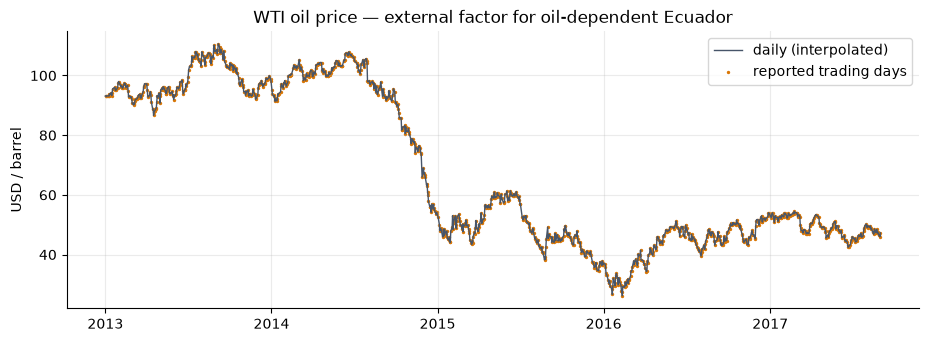

In [5]:
idx = fd.daily_index()
store44 = raw.stores.set_index("store_nbr").loc[44]
cal44 = fd.store_calendar(raw.holidays, store44, idx)
closed44 = fd.closed_days(raw.train, 44, idx)
oil = fd.oil_daily(raw.oil, idx)
print(f"Store 44: {store44.city}, {store44.state}, type {store44.type}, cluster {store44.cluster}")
print("Calendar flag-days 2013-01-01..2017-08-31:", {c: int(cal44[c].sum()) for c in ['holiday','event','quake','work_day']},
      "| closed days:", int(closed44.sum()), "→", [str(d.date()) for d in idx[closed44.to_numpy() == 1]])

fig, ax = plt.subplots()
raw_oil = raw.oil.set_index("date").dcoilwtico
ax.plot(oil.index, oil, color=SLATE, lw=1, label="daily (interpolated)")
ax.scatter(raw_oil.index, raw_oil, s=2, color=AMBER, label="reported trading days")
ax.set_title("WTI oil price — external factor for oil-dependent Ecuador"); ax.set_ylabel("USD / barrel"); ax.legend()
plt.show()

## 3 · EDA — default series: Store 44 · BEVERAGES

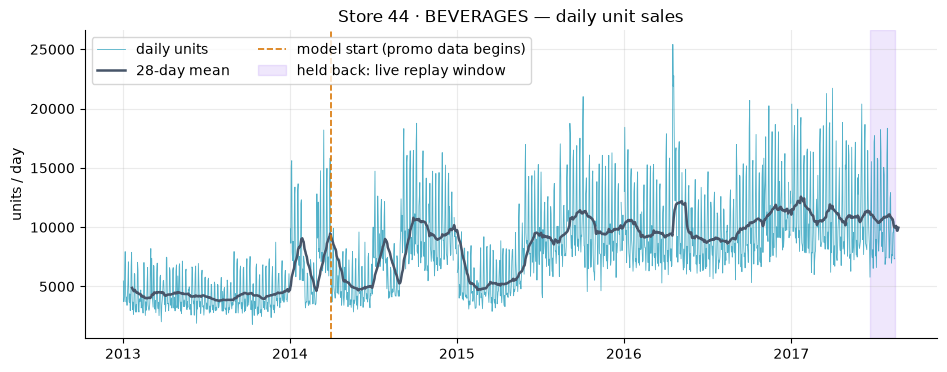

Mean units/day by year: {2013: 4275.0, 2014: 7689.0, 2015: 8114.0, 2016: 10042.0, 2017: 10947.0}


In [6]:
s = fd.extract_series(raw, 44, "BEVERAGES", idx)
obs = (idx <= fd.TRAIN_END) & (closed44.to_numpy() == 0)
y = s.sales.where(obs)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(idx, y, color=CYAN, lw=0.6, alpha=0.7, label="daily units")
ax.plot(idx, y.rolling(28, min_periods=20).mean(), color=SLATE, lw=1.8, label="28-day mean")
ax.axvline(fd.MODEL_START, color=AMBER, ls="--", lw=1.2, label="model start (promo data begins)")
ax.axvspan(fd.REPLAY_START, fd.TRAIN_END, color=VIOLET, alpha=0.12, label="held back: live replay window")
ax.set_title("Store 44 · BEVERAGES — daily unit sales"); ax.set_ylabel("units / day"); ax.legend(loc="upper left", ncols=2)
plt.show()
yearly = y[obs].groupby(idx[obs].year).mean().round(0)
print("Mean units/day by year:", yearly.to_dict())

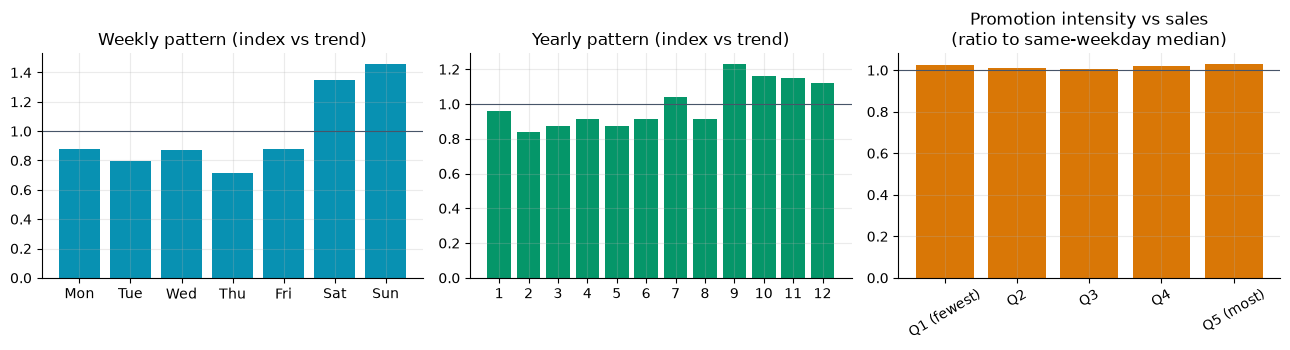

Weekday index: {0: 0.88, 1: 0.794, 2: 0.87, 3: 0.713, 4: 0.88, 5: 1.352, 6: 1.458}
Promotion quintile ratio: {'Q1 (fewest)': 1.025, 'Q2': 1.012, 'Q3': 1.005, 'Q4': 1.022, 'Q5 (most)': 1.03}
December index 1.122 vs annual average 1.000


In [7]:
m = obs & (idx >= fd.MODEL_START)
d = pd.DataFrame({"y": y[m], "promo": s.onpromotion[m], "dow": idx[m].dayofweek, "month": idx[m].month,
                  "hol": cal44.holiday[m], "event": cal44.event[m], "oil": oil[m]})
# Remove trend with a centred 365-day mean so seasonal shapes are comparable across years
d["index"] = d.y / d.y.rolling(365, center=True, min_periods=180).mean()

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
dow = d.groupby("dow")["index"].mean()
axs[0].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow, color=CYAN); axs[0].axhline(1, color=SLATE, lw=0.8)
axs[0].set_title("Weekly pattern (index vs trend)")
mon = d.groupby("month")["index"].mean()
axs[1].bar(range(1, 13), mon, color=GREEN); axs[1].axhline(1, color=SLATE, lw=0.8); axs[1].set_xticks(range(1, 13))
axs[1].set_title("Yearly pattern (index vs trend)")
# Promotion uplift, controlling for weekday: ratio to the same-weekday median of the surrounding 8 weeks
d["dow_med"] = d.groupby("dow")["y"].transform(lambda x: x.rolling(8, center=True, min_periods=4).median())
d["promo_bin"] = pd.qcut(d.promo.rank(method="first"), 5, labels=["Q1 (fewest)", "Q2", "Q3", "Q4", "Q5 (most)"])
up = (d.y / d.dow_med).groupby(d.promo_bin, observed=True).mean()
axs[2].bar(up.index.astype(str), up, color=AMBER); axs[2].axhline(1, color=SLATE, lw=0.8)
axs[2].set_title("Promotion intensity vs sales\n(ratio to same-weekday median)"); axs[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print("Weekday index:", dow.round(3).to_dict())
print("Promotion quintile ratio:", up.round(3).to_dict())
print(f"December index {mon[12]:.3f} vs annual average 1.000")

### Promotion effect — measured, not assumed

The raw promotion–sales correlation (≈0.5) is mostly **shared trend**: both promotions and sales grew from 2014 to 2017.
Two regressions on log sales separate the effects (both include trend, weekday, yearly Fourier terms, holidays, paydays and
the Christmas ramp):

* **β(log promo)** — elasticity to the *level* of promoted items;
* **β(promo surge)** — extra effect of promotions *above their own 28-day norm*, after also controlling for the series' recent level.

In [8]:
prom = []
for store, family in fd.SHORTLIST:
    ii = fd.daily_index(fd.MODEL_START, fd.TRAIN_END)
    ss = fd.extract_series(raw, store, family, ii)
    hol = fd.store_calendar(raw.holidays, raw.stores.set_index("store_nbr").loc[store], ii).holiday.to_numpy()
    op = fd.closed_days(raw.train, store, ii).to_numpy() == 0
    yy, lp = np.log1p(ss.sales.to_numpy()), np.log1p(ss.onpromotion.to_numpy().astype(float))
    X, names = fd.demo_design(ii, ss.onpromotion.to_numpy(), hol)
    b1, *_ = np.linalg.lstsq(X[op], yy[op], rcond=None)
    lvl = pd.Series(np.where(op, yy, np.nan)).rolling(28, min_periods=20).mean().shift(1).to_numpy()
    surge = lp - pd.Series(lp).rolling(28, min_periods=20).mean().shift(1).to_numpy()
    ok = op & ~np.isnan(lvl) & ~np.isnan(surge)
    b2, *_ = np.linalg.lstsq(np.column_stack([X, lvl, surge])[ok], yy[ok], rcond=None)
    on = ss.onpromotion.to_numpy() > 0
    prom.append({"series": fd.series_id(store, family), "β(log promo)": b1[names.index("log_promo")],
                 "uplift per doubling of promoted items": np.expm1(b1[names.index("log_promo")] * np.log(2)),
                 "β(promo surge | level)": b2[-1], "P(promo tomorrow | promo today)": on[1:][on[:-1]].mean()})
pd.DataFrame(prom).set_index("series").style.format({"β(log promo)": "{:+.3f}", "uplift per doubling of promoted items": "{:+.1%}",
                                                     "β(promo surge | level)": "{:+.3f}", "P(promo tomorrow | promo today)": "{:.0%}"})

,β(log promo),uplift per doubling of promoted items,β(promo surge | level),P(promo tomorrow | promo today)
series,,,,
44-BEVERAGES,+0.057,+4.0%,-0.016,97%
44-CLEANING,+0.030,+2.1%,-0.033,95%
44-PERSONAL CARE,+0.038,+2.7%,-0.034,92%
44-GROCERY I,+0.014,+1.0%,-0.009,99%
45-BEVERAGES,+0.090,+6.4%,-0.017,96%
47-BEVERAGES,+0.079,+5.6%,+0.010,97%
3-BEVERAGES,+0.031,+2.2%,-0.048,97%
45-PERSONAL CARE,+0.032,+2.2%,+0.019,92%
1-CLEANING,+0.022,+1.6%,+0.003,90%


**Finding (reported honestly):** at Favorita's *product-family* level, promotions are almost always running (≈97 % persistence)
and their measured effect is **small** — about +1–6 % per doubling of promoted items (BEVERAGES +2–6 %) — while short-term promotion surges add
almost nothing once trend and weekday are controlled. Weekly pattern (Sat/Sun ≈ +35–46 %), holidays (≈ +20 %), December (≈ +12 %)
and trend are the dominant, learnable drivers. Promotions stay in every model as a feature (the slide requires it), and the
dashboard's driver view shows the *measured* effect for the selected series rather than an assumed one.

,mean ratio to same-weekday median,n days
holiday days,1.195,62
event days,0.965,24
normal days,1.010,1141


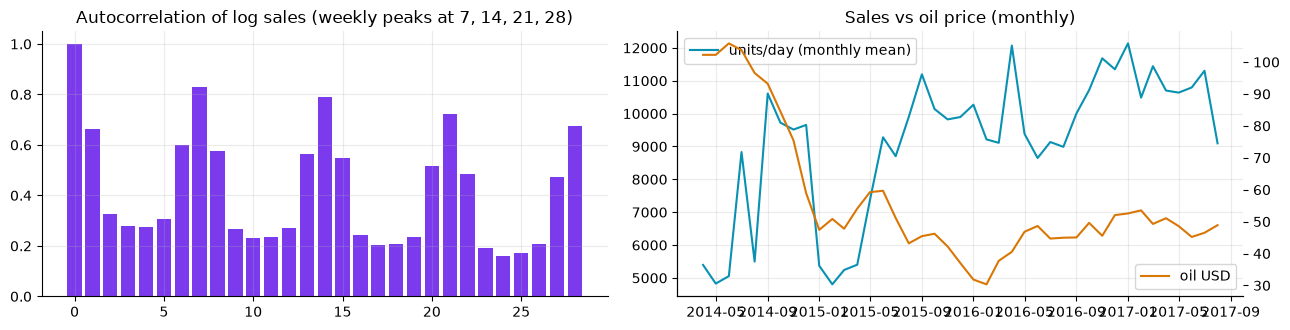

Correlation of monthly sales with oil: -0.46 (confounded with trend — tested as a feature, not assumed)


In [9]:
from statsmodels.tsa.stattools import acf
eff = pd.DataFrame({
    "holiday days": [(d.y / d.dow_med)[d.hol == 1].mean(), int(d.hol.sum())],
    "event days": [(d.y / d.dow_med)[d.event == 1].mean(), int(d.event.sum())],
    "normal days": [(d.y / d.dow_med)[(d.hol == 0) & (d.event == 0)].mean(), int(((d.hol == 0) & (d.event == 0)).sum())],
}, index=["mean ratio to same-weekday median", "n days"]).T
display(eff.style.format({"mean ratio to same-weekday median": "{:.3f}", "n days": "{:.0f}"}))

a = acf(np.log1p(d.y), nlags=28)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
axs[0].bar(range(29), a, color=VIOLET); axs[0].set_title("Autocorrelation of log sales (weekly peaks at 7, 14, 21, 28)")
monthly = d.resample("MS").agg({"y": "mean", "oil": "mean"})
axs[1].plot(monthly.index, monthly.y, color=CYAN, label="units/day (monthly mean)")
ax2 = axs[1].twinx(); ax2.plot(monthly.index, monthly.oil, color=AMBER, label="oil USD"); ax2.grid(False)
axs[1].set_title("Sales vs oil price (monthly)"); axs[1].legend(loc="upper left"); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"Correlation of monthly sales with oil: {monthly.y.corr(monthly.oil):+.2f} (confounded with trend — tested as a feature, not assumed)")

## 4 · Curated shortlist (non-perishable, clean history)

In [10]:
rows = []
for store, family in fd.SHORTLIST:
    ss = fd.extract_series(raw, store, family, idx)
    cl = fd.closed_days(raw.train, store, idx).to_numpy() == 0
    mm = cl & (idx >= fd.MODEL_START) & (idx <= fd.TRAIN_END)
    yy, pp = ss.sales[mm], ss.onpromotion[mm]
    dw = yy.groupby(idx[mm].dayofweek).mean()
    rows.append({"series": fd.series_id(store, family), "mean units/day": yy.mean(), "CV": yy.std() / yy.mean(),
                 "zero open days": int((yy == 0).sum()), "promo days": (pp > 0).mean(),
                 "promo–sales corr": np.corrcoef(np.log1p(pp), np.log1p(yy))[0, 1],
                 "weekday max/min": dw.max() / dw.min(), "fractional": bool(((yy % 1) != 0).any())})
pd.DataFrame(rows).set_index("series").style.format({"mean units/day": "{:,.0f}", "CV": "{:.2f}", "promo days": "{:.0%}",
                                                       "promo–sales corr": "{:.2f}", "weekday max/min": "{:.2f}"})

,mean units/day,CV,zero open days,promo days,promo–sales corr,weekday max/min,fractional
series,,,,,,,
44-BEVERAGES,"9,109",0.41,0,87%,0.50,2.04,False
44-CLEANING,"2,600",0.25,0,87%,0.07,1.67,False
44-PERSONAL CARE,598,0.45,0,71%,0.12,2.39,False
44-GROCERY I,"10,228",0.33,0,92%,0.25,1.87,True
45-BEVERAGES,"7,886",0.46,0,87%,0.57,2.34,False
47-BEVERAGES,"7,444",0.45,0,88%,0.57,2.25,False
3-BEVERAGES,"7,739",0.38,0,92%,0.55,1.88,False
45-PERSONAL CARE,698,0.42,0,71%,0.19,2.51,False
1-CLEANING,655,0.33,0,79%,0.10,3.31,False


## 5 · Slide formula — hand calculation and Monte Carlo cross-check

$$SS = Z\sqrt{\sigma_D^2 L + \bar D^2 \sigma_L^2},\qquad ROP = \bar D L + SS$$

Units: $\bar D,\ \sigma_D$ in units/day; $L,\ \sigma_L$ in days → SS in units. Baseline inputs: trailing 365 calendar days to 2017-08-15, store-open days only.

In [11]:
base = fd.open_window_stats(s.sales, closed44)
Dbar, sD = base["mean"], base["sd"]
print(f"n = {base['n']} open days | D̄ = {Dbar:.4f} units/day | σ_D = {sD:.4f} units/day | CV = {sD/Dbar:.3f}")

def safety_stock(z, sigma_d, L, dbar, sigma_l):
    return z * np.sqrt(sigma_d**2 * L + dbar**2 * sigma_l**2)

grid = []
for L, sL in [(7, 2.0), (5, 1.5)]:
    for SL in (0.90, 0.95, 0.99):
        z = stats.norm.ppf(SL)
        t_d, t_l = sD**2 * L, Dbar**2 * sL**2
        ss = safety_stock(z, sD, L, Dbar, sL)
        grid.append({"L": L, "σ_L": sL, "service level": SL, "Z": z, "σ_D²·L": t_d, "D̄²·σ_L²": t_l,
                     "lead-time share": t_l / (t_d + t_l), "SS": ss, "ROP": Dbar * L + ss, "days of cover": ss / Dbar})
G = pd.DataFrame(grid)
G.style.format({"Z": "{:.4f}", "σ_D²·L": "{:,.0f}", "D̄²·σ_L²": "{:,.0f}", "lead-time share": "{:.0%}",
                "SS": "{:,.1f}", "ROP": "{:,.1f}", "days of cover": "{:.2f}", "service level": "{:.0%}"})

n = 363 open days | D̄ = 10865.3554 units/day | σ_D = 3587.1772 units/day | CV = 0.330


,L,σ_L,service level,Z,σ_D²·L,D̄²·σ_L²,lead-time share,SS,ROP,days of cover
0,7,2.000000,90%,1.2816,"90,074,884","472,223,789",84%,"30,389.2","106,446.7",2.80
1,7,2.000000,95%,1.6449,"90,074,884","472,223,789",84%,"39,004.1","115,061.6",3.59
2,7,2.000000,99%,2.3263,"90,074,884","472,223,789",84%,"55,164.3","131,221.8",5.08
3,5,1.500000,90%,1.2816,"64,339,203","265,625,882",81%,"23,279.3","77,606.1",2.14
4,5,1.500000,95%,1.6449,"64,339,203","265,625,882",81%,"29,878.7","84,205.4",2.75
5,5,1.500000,99%,2.3263,"64,339,203","265,625,882",81%,"42,258.0","96,584.7",3.89


In [12]:
# Step-by-step for the default settings (L = 7 d, σ_L = 2 d, 95 %)
L, sL, SL = 7, 2.0, 0.95
z = stats.norm.ppf(SL)
print(f"Z = Φ⁻¹({SL}) = {z:.6f}")
print(f"σ_D²·L   = {sD:,.2f}² × {L} = {sD**2 * L:,.1f}")
print(f"D̄²·σ_L² = {Dbar:,.2f}² × {sL}² = {Dbar**2 * sL**2:,.1f}")
SS = safety_stock(z, sD, L, Dbar, sL)
print(f"SS  = {z:.4f} × √({sD**2 * L:,.1f} + {Dbar**2 * sL**2:,.1f}) = {SS:,.2f} units")
print(f"ROP = {Dbar:,.2f} × {L} + {SS:,.2f} = {Dbar * L + SS:,.2f} units")

Z = Φ⁻¹(0.95) = 1.644854
σ_D²·L   = 3,587.18² × 7 = 90,074,883.8
D̄²·σ_L² = 10,865.36² × 2.0² = 472,223,789.4
SS  = 1.6449 × √(90,074,883.8 + 472,223,789.4) = 39,004.15 units
ROP = 10,865.36 × 7 + 39,004.15 = 115,061.63 units


,SS (Monte Carlo),SS (formula),difference,P(stockout) at formula ROP
normal L (formula's assumption),"39,810","39,004",+2.1%,5.34%
gamma L (right-skewed delays),"42,242","39,004",+8.3%,6.19%


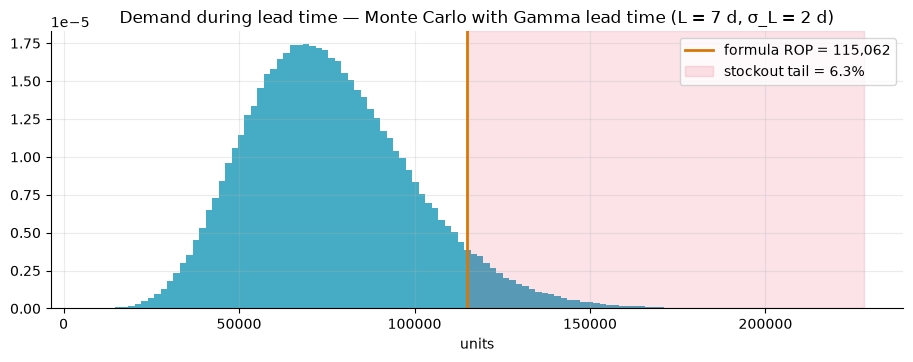

In [13]:
# Monte Carlo cross-check: demand during lead time (DDLT) = sum of L daily demands, L random.
rng = np.random.default_rng(20261111)
N = 400_000
def mc(lead_times):
    lt = lead_times[lead_times > 0]
    ddlt = rng.normal(Dbar * lt, sD * np.sqrt(lt))   # Σ of L iid N(D̄, σ_D²) given L
    return ddlt
k, theta = (L / sL) ** 2, sL ** 2 / L
res = {}
for name, draws in {"normal L (formula's assumption)": rng.normal(L, sL, N), "gamma L (right-skewed delays)": rng.gamma(k, theta, N)}.items():
    dd = mc(draws)
    ss_mc = np.quantile(dd, SL) - dd.mean()
    res[name] = {"SS (Monte Carlo)": ss_mc, "SS (formula)": SS, "difference": ss_mc / SS - 1,
                 "P(stockout) at formula ROP": float((dd > Dbar * L + SS).mean())}
MC = pd.DataFrame(res).T
display(MC.style.format({"SS (Monte Carlo)": "{:,.0f}", "SS (formula)": "{:,.0f}", "difference": "{:+.1%}", "P(stockout) at formula ROP": "{:.2%}"}))

fig, ax = plt.subplots()
dd = mc(rng.gamma(k, theta, N))
ax.hist(dd, bins=120, color=CYAN, alpha=0.75, density=True)
rop = Dbar * L + SS
ax.axvline(rop, color=AMBER, lw=2, label=f"formula ROP = {rop:,.0f}")
ax.axvspan(rop, dd.max(), color=RED, alpha=0.12, label=f"stockout tail = {(dd > rop).mean():.1%}")
ax.set_title("Demand during lead time — Monte Carlo with Gamma lead time (L = 7 d, σ_L = 2 d)"); ax.set_xlabel("units"); ax.legend()
plt.show()

**Reading:** at these settings **≈84 % of the buffer covers lead-time uncertainty**, not demand swings. Under the formula's own
assumptions the Monte Carlo agrees within ≈3 % (the compound distribution is not exactly normal); with realistic right-skewed
(Gamma) delays, the formula's ROP gives a stockout probability above the intended 5 % — the gap the slide's Monte Carlo step is designed to expose.

## 6 · Synthetic demo generator — parameters and validation

In [14]:
demo = json.loads((ROOT / "app" / "src" / "data" / "demo-params.json").read_text())
print(demo["source"], "| fit R² =", round(demo["fit"]["r2"], 3), "| AR(1) =", round(demo["noise"]["ar1"], 3))
coef = pd.Series(demo["coefficients"])

# Re-simulate in Python exactly as the TypeScript generator will, then compare summary statistics with the real series.
sim_idx = fd.daily_index(fd.MODEL_START, fd.TRAIN_END)
r = np.random.default_rng(1)
on = np.zeros(len(sim_idx), bool)
for t in range(1, len(sim_idx)):
    p = demo["promo"]["pOnGivenOn"] if on[t - 1] else demo["promo"]["pOnGivenOff"]
    on[t] = r.random() < p
promo = np.where(on, np.round(np.exp(r.normal(demo["promo"]["logCountMean"], demo["promo"]["logCountSd"], len(sim_idx)))), 0)
X, names = fd.demo_design(sim_idx, promo, cal44.holiday.reindex(sim_idx).to_numpy())
eps = np.zeros(len(sim_idx))
for t in range(1, len(sim_idx)):
    eps[t] = demo["noise"]["ar1"] * eps[t - 1] + r.normal(0, demo["noise"]["innovationSd"])
synthetic = np.expm1(X @ coef[names].to_numpy() + eps)
real = s.sales.reindex(sim_idx)[closed44.reindex(sim_idx).to_numpy() == 0]
cmp_ = pd.DataFrame({
    "real": [real.mean(), real.std() / real.mean(), real.groupby(real.index.dayofweek).mean().pipe(lambda x: x.max() / x.min()),
             pd.Series(np.log1p(real.to_numpy())).autocorr(7)],
    "synthetic": [synthetic.mean(), synthetic.std() / synthetic.mean(),
                  pd.Series(synthetic).groupby(sim_idx.dayofweek).mean().pipe(lambda x: x.max() / x.min()),
                  pd.Series(np.log1p(synthetic)).autocorr(7)]},
    index=["mean units/day", "CV", "weekday max/min", "lag-7 autocorrelation (log)"])
cmp_.style.format("{:.3f}")

Estimated from Favorita store 44 BEVERAGES, 2014-04-01..2017-08-15 | fit R² = 0.696 | AR(1) = 0.711


,real,synthetic
mean units/day,9109.272,9084.375
CV,0.406,0.410
weekday max/min,2.044,2.018
lag-7 autocorrelation (log),0.835,0.643


## 7 · Golden values for the TypeScript unit tests

In [15]:
probs = [0.001, 0.01, 0.05, 0.1, 0.5, 0.8, 0.9, 0.95, 0.975, 0.99, 0.995, 0.999, 0.9999]
golden = {
    "series": "44-BEVERAGES",
    "baselineWindow": {"start": "2016-08-16", "end": str(fd.TRAIN_END.date()), **base},
    "formula": [{"L": g["L"], "sigmaL": g["σ_L"], "serviceLevel": g["service level"], "z": g["Z"],
                 "termDemand": g["σ_D²·L"], "termLeadTime": g["D̄²·σ_L²"], "ss": g["SS"], "rop": g["ROP"]} for g in grid],
    "inverseNormal": [{"p": p, "z": float(stats.norm.ppf(p))} for p in probs],
    "monteCarlo": {"N": N, "normalL": {"ssDiff": float(MC.iloc[0]["difference"])},
                   "gammaL": {"ssDiff": float(MC.iloc[1]["difference"]), "pStockoutAtFormulaRop": float(MC.iloc[1]["P(stockout) at formula ROP"])}},
    "calendar": {"days": len(idx), "store44": {c: int(cal44[c].sum()) for c in ["holiday", "event", "quake", "work_day"]}
                 | {"closed": int(closed44.sum())}},
    "promoDaysSinceModelStart": int((s.onpromotion[(idx >= fd.MODEL_START) & (idx <= fd.TRAIN_END)] > 0).sum()),
    "spotChecks": {"payday": {"2017-01-15": 1, "2017-01-31": 1, "2017-02-28": 1, "2017-02-14": 0},
                   "xmasRamp": {"2016-12-12": 0.5, "2016-12-24": 1.0, "2016-12-26": 0.0}},
}
out = ROOT / "app" / "tests" / "golden" / "favorita-golden.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(golden, indent=2))
print("wrote", out.relative_to(ROOT))
print(json.dumps({k: golden[k] for k in ["baselineWindow", "calendar", "promoDaysSinceModelStart"]}, indent=1))

wrote app\tests\golden\favorita-golden.json
{
 "baselineWindow": {
  "start": "2016-08-16",
  "end": "2017-08-15",
  "n": 363,
  "mean": 10865.355371900827,
  "sd": 3587.177238318146
 },
 "calendar": {
  "days": 1704,
  "store44": {
   "holiday": 90,
   "event": 25,
   "quake": 31,
   "work_day": 5,
   "closed": 9
  }
 },
 "promoDaysSinceModelStart": 1068
}


## 8 · Forecast models — selection and comparison (Part B)

**Protocol (identical for every model):** forecast origin = 2017-06-20 (the day before the live-replay window),
**6 rolling folds × 28 days** (the 24 weeks before it). At each fold origin a model sees only data up to that day,
forecasts 28 days ahead, and is scored on store-open days. Metrics: WAPE (Σ|error| / Σ sales), bias, MASE
(MAE ÷ in-sample seasonal-naive MAE).

| Group | Model | Where it runs |
|---|---|---|
| Time series | Holt-Winters ETS (damped trend, weekly season, log scale) | **Browser** (TypeScript) |
| Regression | Ridge dynamic regression (drivers + lags) | **Browser** (TypeScript) |
| Deep learning | LSTM (28-day window + target-day drivers) | **Browser** (TensorFlow.js, WebAssembly) — rolling: trained once, then fine-tuned at each later origin |
| AI combination | Adaptive ensemble (weights ∝ 1/WAPE from *earlier* folds only) | **Browser** |
| Reference | LightGBM, SARIMAX (1,1,1)×(1,0,1)₇ + regressors, Keras LSTM (same architecture, retrained per fold) | Python (this notebook) |
| Benchmarks | 28-day moving average (what a classic calculator uses), seasonal naive | both |

Browser-model results come from `app/scripts/backtestReport.ts` (run with `npx vite-node`), which executes the
production TypeScript code on the same data pack and writes `data/processed/ts-backtest.json`.

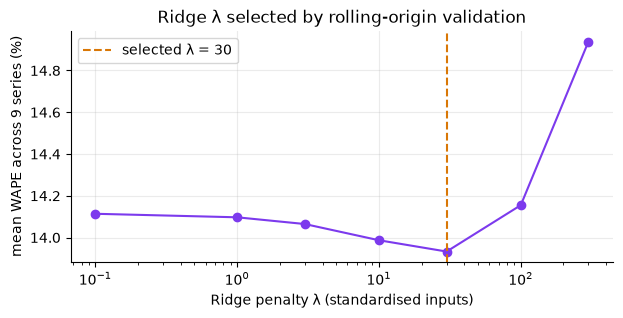

lambda,0.1,1.0,3.0,10.0,30.0,100.0,300.0
meanWape,14.11,14.1,14.06,13.99,13.93,14.15,14.94


In [16]:
ts = json.loads((ROOT / "data" / "processed" / "ts-backtest.json").read_text())
lam = pd.DataFrame(ts["lambdaSelection"]["grid"]).set_index("lambda")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(lam.index, lam.meanWape * 100, "o-", color=VIOLET); ax.set_xscale("log")
ax.axvline(ts["lambdaSelection"]["best"], color=AMBER, ls="--", label=f"selected λ = {ts['lambdaSelection']['best']}")
ax.set_xlabel("Ridge penalty λ (standardised inputs)"); ax.set_ylabel("mean WAPE across 9 series (%)"); ax.legend()
ax.set_title("Ridge λ selected by rolling-origin validation"); plt.show()
lam.assign(meanWape=lambda d: (d.meanWape * 100).round(2)).T

In [17]:
rows = []
for r in ts["results"]:
    for m in r["models"]:
        rows.append({"series": r["series"], "model": m["model"], "WAPE": m["wape"], "MASE": m["mase"], "bias": m["bias"]})
browser = pd.DataFrame(rows)
order = ["ensemble", "ridge", "ets", "lstm", "snaive", "ma28"]
wape_tbl = browser.pivot(index="series", columns="model", values="WAPE")[order]
display(wape_tbl.style.format("{:.1%}").highlight_min(axis=1, color="#d1fae5"))
print("LSTM training time in the engine (incl. 6-fold rolling backtest):",
      {r["series"]: f"{r['seconds']:.0f}s / {r['lstmEpochs']} epochs" for r in ts["results"]})

model,ensemble,ridge,ets,lstm,snaive,ma28
series,,,,,,
1-CLEANING,13.8%,12.2%,20.0%,13.1%,19.6%,25.4%
3-BEVERAGES,12.5%,13.4%,15.4%,12.5%,18.4%,22.6%
44-BEVERAGES,12.0%,12.5%,15.2%,12.7%,21.3%,28.2%
44-CLEANING,11.7%,11.7%,18.4%,11.5%,19.7%,21.1%
44-GROCERY I,13.0%,12.1%,17.7%,15.3%,20.1%,26.9%
44-PERSONAL CARE,17.0%,17.4%,27.2%,16.0%,27.6%,35.8%
45-BEVERAGES,12.8%,14.3%,18.1%,15.0%,22.4%,29.6%
45-PERSONAL CARE,19.9%,15.4%,35.0%,21.2%,30.3%,32.1%
47-BEVERAGES,14.1%,16.5%,16.5%,15.7%,23.5%,30.0%


LSTM training time in the engine (incl. 6-fold rolling backtest): {'44-BEVERAGES': '67s / 59 epochs', '44-CLEANING': '87s / 51 epochs', '44-PERSONAL CARE': '57s / 46 epochs', '44-GROCERY I': '63s / 52 epochs', '45-BEVERAGES': '74s / 58 epochs', '47-BEVERAGES': '45s / 48 epochs', '3-BEVERAGES': '61s / 61 epochs', '45-PERSONAL CARE': '46s / 49 epochs', '1-CLEANING': '43s / 46 epochs'}


In [18]:
import time, os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import reference_models as rm
pack = rm.load_pack()
REPRESENTATIVE = ["44-BEVERAGES", "44-CLEANING", "47-BEVERAGES"]   # heavy models (SARIMAX, Keras) on 3 series
ref_rows, t0 = [], time.time()
for sid in [r["series"] for r in ts["results"]]:
    models = ["lightgbm"] + (["sarimax", "keras_lstm"] if sid in REPRESENTATIVE else [])
    for m, met in rm.evaluate(pack, sid, models).items():
        ref_rows.append({"series": sid, "model": m, "WAPE": met["wape"], "MASE": met["mase"], "bias": met["bias"]})
ref = pd.DataFrame(ref_rows)
print(f"reference models evaluated in {time.time() - t0:.0f}s")

reference models evaluated in 434s


In [19]:
allm = pd.concat([browser, ref], ignore_index=True)
labels = {"ensemble": "Adaptive ensemble (browser)", "ridge": "Ridge regression (browser)", "ets": "Holt-Winters ETS (browser)",
          "lstm": "LSTM — TF.js (browser)", "lightgbm": "LightGBM (Python ref.)", "sarimax": "SARIMAX (Python ref.)",
          "keras_lstm": "LSTM — Keras (Python ref.)", "snaive": "Seasonal naive (benchmark)", "ma28": "28-day moving average (benchmark)"}
def summary(df, series):
    d = df[df.series.isin(series)]
    out = d.groupby("model").agg(mean_WAPE=("WAPE", "mean"), mean_MASE=("MASE", "mean"), mean_bias=("bias", "mean"), series=("series", "nunique"))
    return out.rename(index=labels).sort_values("mean_WAPE")
print("All 9 series (browser models, LightGBM, benchmarks):")
display(summary(allm[~allm.model.isin(["sarimax", "keras_lstm"])], wape_tbl.index).style.format({"mean_WAPE": "{:.1%}", "mean_MASE": "{:.2f}", "mean_bias": "{:+.1%}"}))
print("3 representative series (all models):")
display(summary(allm, REPRESENTATIVE).style.format({"mean_WAPE": "{:.1%}", "mean_MASE": "{:.2f}", "mean_bias": "{:+.1%}"}))

All 9 series (browser models, LightGBM, benchmarks):


,mean_WAPE,mean_MASE,mean_bias,series
model,,,,
Ridge regression (browser),13.9%,0.89,-6.6%,9
Adaptive ensemble (browser),14.1%,0.88,-1.4%,9
LSTM — TF.js (browser),14.8%,0.93,-1.0%,9
LightGBM (Python ref.),15.2%,0.97,-4.5%,9
Holt-Winters ETS (browser),20.4%,1.24,+5.2%,9
Seasonal naive (benchmark),22.6%,1.42,+0.0%,9
28-day moving average (benchmark),28.0%,1.78,+1.6%,9


3 representative series (all models):


,mean_WAPE,mean_MASE,mean_bias,series
model,,,,
Adaptive ensemble (browser),12.6%,0.92,-2.6%,3
LSTM — TF.js (browser),13.3%,0.97,-2.7%,3
SARIMAX (Python ref.),13.4%,0.97,-0.5%,3
Ridge regression (browser),13.6%,0.99,-8.5%,3
LightGBM (Python ref.),15.0%,1.10,-5.8%,3
Holt-Winters ETS (browser),16.7%,1.19,+5.0%,3
LSTM — Keras (Python ref.),17.3%,1.25,+8.7%,3
Seasonal naive (benchmark),21.5%,1.56,+0.3%,3
28-day moving average (benchmark),26.5%,1.94,+0.5%,3


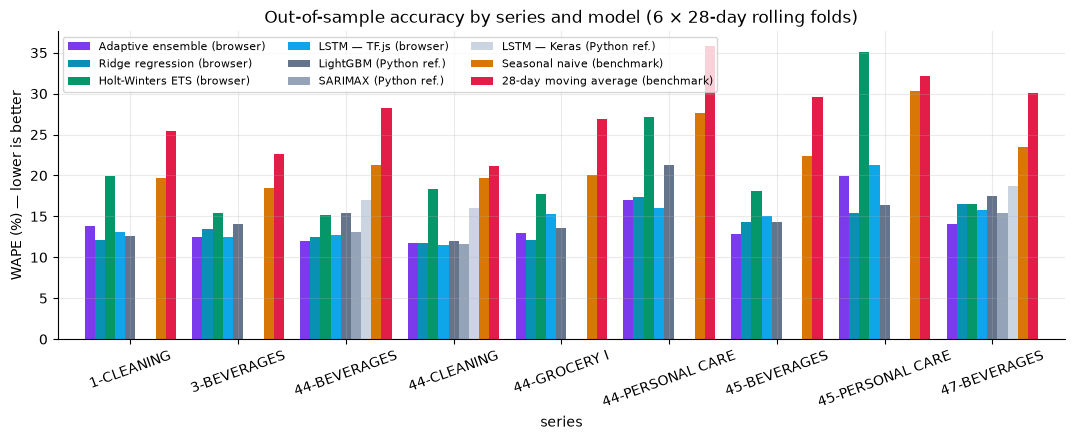

44-BEVERAGES: adaptive-ensemble weights {'ets': 0.293, 'ridge': 0.356, 'lstm': 0.351}
Driver effects from the Ridge model (conditional on recent sales level): {'weekday': [1, 0.91, 0.99, 0.84, 0.99, 1.44, 1.53], 'promoPerDoubling': 0.008, 'holiday': 0.208, 'event': -0.033, 'earthquake': 0.062, 'payday': 0.005, 'christmasEve': -0.029, 'oilPer10': 0.002}


In [20]:
pv = allm.pivot_table(index="series", columns="model", values="WAPE")
cols = [c for c in ["ensemble", "ridge", "ets", "lstm", "lightgbm", "sarimax", "keras_lstm", "snaive", "ma28"] if c in pv]
colors = {"ensemble": VIOLET, "ridge": CYAN, "ets": GREEN, "lstm": "#0EA5E9", "lightgbm": "#64748B", "sarimax": "#94A3B8",
          "keras_lstm": "#CBD5E1", "snaive": AMBER, "ma28": RED}
ax = (pv[cols] * 100).plot(kind="bar", figsize=(13, 4), width=0.85, color=[colors[c] for c in cols])
ax.set_ylabel("WAPE (%) — lower is better"); ax.set_title("Out-of-sample accuracy by series and model (6 × 28-day rolling folds)")
ax.legend([labels[c] for c in cols], ncols=3, fontsize=8); plt.xticks(rotation=20); plt.show()

d = ts["results"][0]
w = pd.Series(d["weights"]).rename("weight")
print(f"{d['series']}: adaptive-ensemble weights", w.round(3).to_dict())
print("Driver effects from the Ridge model (conditional on recent sales level):",
      {k: (round(v, 3) if not isinstance(v, list) else [round(x, 2) for x in v]) for k, v in d["drivers"].items()})

**How to read this.** WAPE is the share of units mis-forecast over 28 days ahead. The classic calculator's
moving average ignores weekdays, holidays and trend, so every model is judged against it and against the
stricter seasonal-naive benchmark. Python reference models show whether the lighter in-browser models give up
accuracy compared with heavier tools. The section's conclusions are printed below from the numbers above,
so they stay correct if the data or models change.

In [21]:
s9 = summary(allm[~allm.model.isin(["sarimax", "keras_lstm"])], wape_tbl.index)["mean_WAPE"]
s3 = summary(allm, REPRESENTATIVE)["mean_WAPE"]
best9 = s9.index[0]
gain = 1 - s9[labels["ensemble"]] / s9[labels["ma28"]]
print(f"• Best on all 9 series: {best9} ({s9.iloc[0]:.1%} WAPE).")
print(f"• Adaptive ensemble vs 28-day moving average: {s9[labels['ensemble']]:.1%} vs {s9[labels['ma28']]:.1%} "
      f"→ {gain:.0%} fewer units mis-forecast.")
print(f"• Ensemble vs seasonal naive: {s9[labels['ensemble']]:.1%} vs {s9[labels['snaive']]:.1%}.")
print(f"• Browser LSTM vs Keras LSTM (3 series): {s3[labels['lstm']]:.1%} vs {s3[labels['keras_lstm']]:.1%}; "
      f"best Python reference on 3 series: {min((s3[labels[m]], labels[m]) for m in ['lightgbm', 'sarimax', 'keras_lstm'])[1]}.")

• Best on all 9 series: Ridge regression (browser) (13.9% WAPE).
• Adaptive ensemble vs 28-day moving average: 14.1% vs 28.0% → 50% fewer units mis-forecast.
• Ensemble vs seasonal naive: 14.1% vs 22.6%.
• Browser LSTM vs Keras LSTM (3 series): 13.3% vs 17.3%; best Python reference on 3 series: SARIMAX (Python ref.).


## 9 · Dynamic safety stock and Monte Carlo (Part C)

Orders placed on **2017-06-20** (start of the live-replay window), service level 95 %, lead time Gamma(L = 7 d, σ_L = 2 d).

| | D̄ (units/day) | σ in the formula | Reorder point |
|---|---|---|---|
| **Baseline** (classic calculator) | mean of the last 365 days | σ_D of raw daily sales (weekend/holiday swings counted as risk) | D̄·L + SS |
| **AI-enhanced** | forecast demand over the next L days ÷ L | σ_e = RMSE of out-of-sample ensemble errors at horizons 1–7 | forecast lead-time demand + SS |

The **Monte Carlo** then simulates 200 000 replenishment cycles using the AI forecast, real out-of-sample forecast
errors (moving-block bootstrap) and Gamma lead times, to find the buffer actually needed and the stockout risk of each
reorder point. Values come from the production TypeScript (`app/scripts/safetyReport.ts` → `ts-safety.json`); this
section recomputes the formula independently and re-implements the Monte Carlo in NumPy.

In [22]:
sr = json.loads((ROOT / "data" / "processed" / "ts-safety.json").read_text())
z95 = stats.norm.ppf(0.95)
L_, sL_ = sr["params"]["leadTime"]["mean"], sr["params"]["leadTime"]["sd"]
recomputed, rows = [], []
for r in sr["rows"]:
    for kind, sig in (("baseline", "sigmaD"), ("ai", "sigmaE")):
        x = r[kind]
        ss = z95 * np.sqrt(x[sig] ** 2 * L_ + x["dBar"] ** 2 * sL_ ** 2)
        recomputed.append(abs(ss - x["ss"]) / x["ss"])
    rows.append({"series": r["series"], "baseline SS": r["baseline"]["ss"], "AI SS": r["ai"]["ss"],
                 "σ_D (raw)": r["baseline"]["sigmaD"], "σ_e (forecast error)": r["ai"]["sigmaE"],
                 "baseline ROP": r["baseline"]["rop"], "AI ROP": r["ai"]["rop"], "MC ROP needed (95%)": r["mc"]["ropNeeded"],
                 "P(stockout) @ baseline ROP": r["mc"]["pStockoutAtBaselineRop"], "P(stockout) @ AI ROP": r["mc"]["pStockoutAtAiRop"]})
print(f"Formula recomputed in Python from the same inputs: max relative difference vs TypeScript = {max(recomputed):.1e}")
print("Formula vs Monte Carlo under the formula's own assumptions (TypeScript, 400k trials):",
      {k: f"SS {v['diff']:+.1%}, P(stockout) {v['pStockout']:.2%}" for k, v in sr["formulaCheck"].items()})
T = pd.DataFrame(rows).set_index("series")
T.style.format({c: "{:,.0f}" for c in T.columns if "P(" not in c} | {c: "{:.1%}" for c in T.columns if "P(" in c})

Formula recomputed in Python from the same inputs: max relative difference vs TypeScript = 0.0e+00
Formula vs Monte Carlo under the formula's own assumptions (TypeScript, 400k trials): {'normal': 'SS +2.1%, P(stockout) 5.33%', 'gamma': 'SS +8.7%, P(stockout) 6.25%'}


,baseline SS,AI SS,σ_D (raw),σ_e (forecast error),baseline ROP,AI ROP,MC ROP needed (95%),P(stockout) @ baseline ROP,P(stockout) @ AI ROP
series,,,,,,,,,
44-BEVERAGES,"38,212","38,787","3,518","2,023","112,713","119,164","124,697",9.1%,6.5%
44-CLEANING,"9,087","8,623",680,489,"27,369","26,402","27,739",5.5%,6.9%
44-PERSONAL CARE,"2,364","2,276",273,192,"6,713","6,779","7,152",7.4%,7.0%
44-GROCERY I,"39,232","36,023","3,467","2,448","116,292","109,246","111,654",3.9%,5.7%
45-BEVERAGES,"35,258","36,123","3,492","2,267","102,954","110,065","112,643",8.7%,5.8%
47-BEVERAGES,"33,348","37,529","3,422","1,918","96,837","115,386","121,576",21.3%,7.0%
3-BEVERAGES,"32,237","32,152","2,563","1,683","96,593","98,769","104,880",8.5%,7.4%
45-PERSONAL CARE,"2,791","2,684",306,255,"8,007","7,882","7,973",4.9%,5.4%
1-CLEANING,"2,371","2,316",215,186,"7,007","6,934","8,242",14.6%,15.4%


44-BEVERAGES: Monte Carlo buffer needed — TypeScript 41,169 vs NumPy 41,476 (+0.75%); ROP needed 124,697 vs 125,045


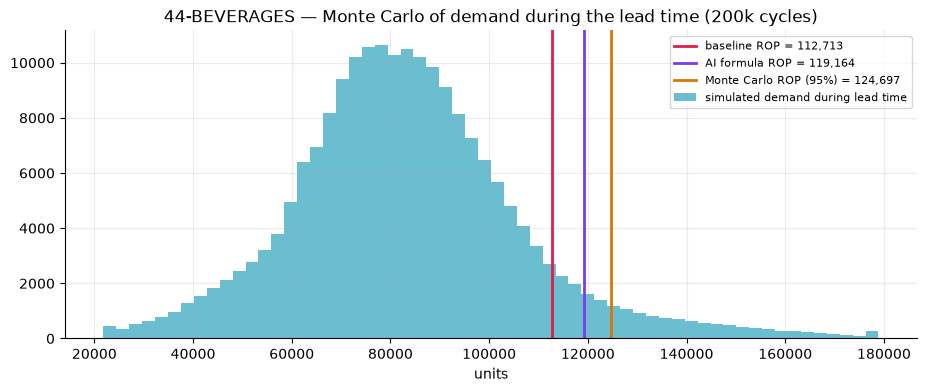

In [23]:
d = sr["detail"]
fc = np.array(d["forecast"]); rel = np.array([[np.nan if v is None else v for v in b] for b in d["relErrors"]])

def forecast_at(f, k):
    while k >= len(f): k -= 7
    return f[k]

def numpy_mc(forecast, rel, L, sL, sl, N, seed):
    # Independent re-implementation of the TypeScript Monte Carlo: Gamma lead time, weekday-aligned
    # weekly block bootstrap of out-of-sample relative errors (one real week of errors per simulated week).
    rng = np.random.default_rng(seed)
    lt = rng.gamma((L / sL) ** 2, sL ** 2 / L, N)
    days, frac = np.floor(lt).astype(int), lt - np.floor(lt)
    folds, H = rel.shape
    weeks = max(1, min(3, H // 7))
    total = np.zeros(N)
    for k in range(days.max() + 1):
        if k % 7 == 0:
            j, b = rng.integers(0, folds, N), rng.integers(0, weeks, N)
        f = forecast_at(forecast, k)
        if f <= 0: continue
        r = rel[j, 7 * b + k % 7]
        dmd = np.maximum(0, f * (1 + np.where(np.isfinite(r), r, 0)))
        total += np.where(k < days, 1.0, np.where(k == days, frac, 0.0)) * dmd
    q = np.quantile(total, sl)
    return q - total.mean(), q, total

ss_np, rop_np, sims = numpy_mc(fc, rel, L_, sL_, 0.95, 400_000, 123)
print(f"{d['series']}: Monte Carlo buffer needed — TypeScript {d['mc']['ssNeeded']:,.0f} vs NumPy {ss_np:,.0f} "
      f"({ss_np / d['mc']['ssNeeded'] - 1:+.2%}); ROP needed {d['mc']['ropNeeded']:,.0f} vs {rop_np:,.0f}")

row = next(r for r in sr["rows"] if r["series"] == d["series"])
h = d["mc"]["histogram"]; edges = np.array(h["edges"]); mid = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(mid, h["counts"], width=np.diff(edges), color=CYAN, alpha=0.6, label="simulated demand during lead time")
for x, c, lab in [(row["baseline"]["rop"], RED, "baseline ROP"), (row["ai"]["rop"], VIOLET, "AI formula ROP"), (d["mc"]["ropNeeded"], AMBER, "Monte Carlo ROP (95%)")]:
    ax.axvline(x, color=c, lw=2, label=f"{lab} = {x:,.0f}")
ax.set_title(f"{d['series']} — Monte Carlo of demand during the lead time (200k cycles)"); ax.set_xlabel("units"); ax.legend(fontsize=8)
plt.show()

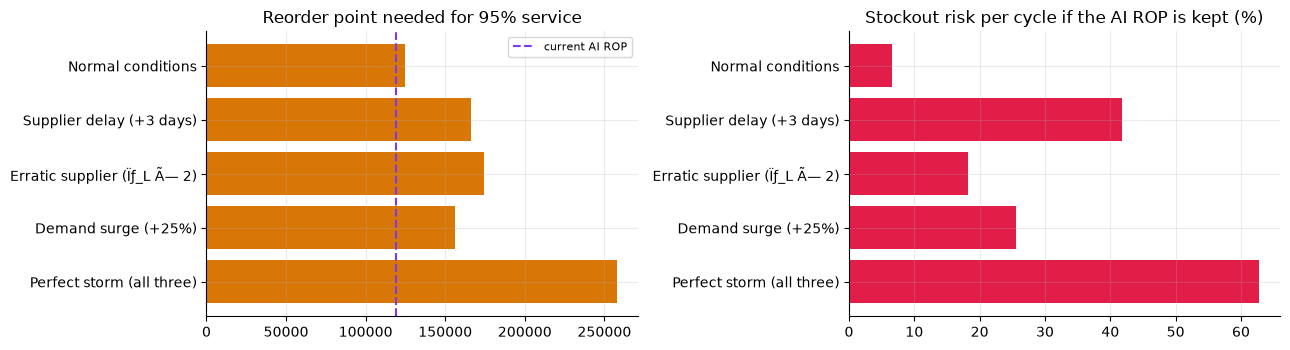

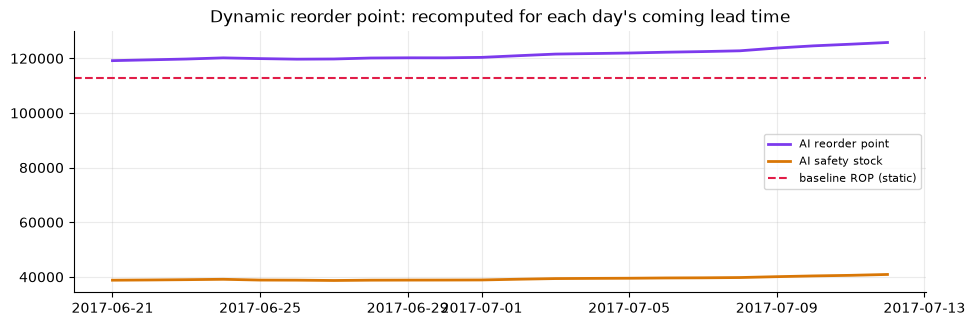

In [24]:
sc = pd.DataFrame(d["scenarios"]).set_index("label")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
axs[0].barh(sc.index, sc.ropNeeded, color=AMBER); axs[0].axvline(row["ai"]["rop"], color=VIOLET, ls="--", label="current AI ROP")
axs[0].set_title("Reorder point needed for 95% service"); axs[0].legend(fontsize=8); axs[0].invert_yaxis()
axs[1].barh(sc.index, sc.pStockout * 100, color=RED); axs[1].set_title("Stockout risk per cycle if the AI ROP is kept (%)"); axs[1].invert_yaxis()
plt.tight_layout(); plt.show()

p = d["path"]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(pd.to_datetime(p["dates"]), p["reorderPoint"], color=VIOLET, lw=2, label="AI reorder point")
ax.plot(pd.to_datetime(p["dates"]), p["safetyStock"], color=AMBER, lw=2, label="AI safety stock")
ax.axhline(row["baseline"]["rop"], color=RED, ls="--", label="baseline ROP (static)")
ax.set_title("Dynamic reorder point: recomputed for each day's coming lead time"); ax.legend(fontsize=8); plt.show()

In [25]:
gap = (T["MC ROP needed (95%)"] / T["AI ROP"] - 1)
print(f"• σ_e (forecast error) is {np.mean(T['σ_e (forecast error)'] / T['σ_D (raw)']):.0%} of raw σ_D on average: the forecast explains most day-to-day variation.")
print(f"• AI safety stock is {np.mean(T['AI SS'] / T['baseline SS'] - 1):+.1%} vs baseline on average (lead-time variability still dominates the buffer).")
print(f"• Stockout risk per cycle (Monte Carlo, AI demand view): baseline ROP {T['P(stockout) @ baseline ROP'].mean():.1%} on average "
      f"(range {T['P(stockout) @ baseline ROP'].min():.1%}–{T['P(stockout) @ baseline ROP'].max():.1%}), "
      f"AI formula ROP {T['P(stockout) @ AI ROP'].mean():.1%} — target 5.0%.")
print(f"• Monte Carlo ROP needed is {gap.mean():+.1%} vs the AI formula ROP on average → the formula's normal approximation "
      f"{'under' if gap.mean() > 0 else 'over'}-protects; the dashboard can use the Monte Carlo reorder point.")

• σ_e (forecast error) is 70% of raw σ_D on average: the forecast explains most day-to-day variation.
• AI safety stock is -0.8% vs baseline on average (lead-time variability still dominates the buffer).
• Stockout risk per cycle (Monte Carlo, AI demand view): baseline ROP 9.3% on average (range 3.9%–21.3%), AI formula ROP 7.5% — target 5.0%.
• Monte Carlo ROP needed is +5.7% vs the AI formula ROP on average → the formula's normal approximation under-protects; the dashboard can use the Monte Carlo reorder point.


## 10 · Bayesian optimisation of the reorder policy under constraints (Part D)

**Problem.** Choose the policy that minimises expected cost per day (holding + ordering + lost-sales penalty) subject to:
fill rate ≥ 98 %, 95th-percentile peak stock ≤ storage capacity (18 days of demand), average inventory value ≤ budget
(12 days of demand at cost), deliveries ≤ 3 per week. The AI policy is dynamic, R_t = forecast lead-time demand_t + b, and
the optimiser chooses the buffer b and the order quantity Q.

**Evaluation.** 64 simulated 13-week demand paths (forecast × real out-of-sample errors), Gamma lead times, and common
random numbers: every candidate is scored on the same paths. **Bayesian optimisation**: 8 Halton starting points + 30
iterations of a Matérn-5/2 Gaussian process with constrained Expected Improvement (38 simulations).
**Validation**: an exhaustive 30 × 30 grid (900 simulations), i.e. the "manual parameter sweep" the slide replaces.

Cost assumptions (adjustable on the dashboard): unit cost $0.70, holding 25 %/yr, $120 per order, $0.50 per lost unit.
Source: `app/scripts/optimizeReport.ts` → `ts-optimize.json`. In this offline sweep the forecasts use the ETS + Ridge
ensemble; the LSTM is left out only for speed.

In [26]:
op = json.loads((ROOT / "data" / "processed" / "ts-optimize.json").read_text())
rows = []
for r in op["rows"]:
    D = r["meanDemand"]
    rows.append({"series": r["series"],
                 "baseline $/day": r["baseline"]["cost"], "baseline feasible": r["baseline"]["feasible"], "baseline fill": r["baseline"]["fill"],
                 "AI formula $/day": r["aiFormula"]["cost"], "AI formula feasible": r["aiFormula"]["feasible"],
                 "BO $/day": r["bo"]["cost"], "BO fill": r["bo"]["fill"], "BO buffer (days)": r["bo"]["x"][0] / D, "BO Q (days)": r["bo"]["x"][1] / D,
                 "grid $/day": r["grid"]["cost"], "BO vs grid": r["bo"]["cost"] / r["grid"]["cost"] - 1,
                 "EOQ (days)": r["eoq"] / D, "BO peak (days)": r["bo"]["peak"] / D})
O = pd.DataFrame(rows).set_index("series")
O.style.format({"baseline $/day": "${:,.0f}", "AI formula $/day": "${:,.0f}", "BO $/day": "${:,.0f}", "grid $/day": "${:,.0f}",
                "baseline fill": "{:.1%}", "BO fill": "{:.2%}", "BO vs grid": "{:+.2%}", "BO buffer (days)": "{:.1f}",
                "BO Q (days)": "{:.1f}", "EOQ (days)": "{:.1f}", "BO peak (days)": "{:.1f}"})

,baseline $/day,baseline feasible,baseline fill,AI formula $/day,AI formula feasible,BO $/day,BO fill,BO buffer (days),BO Q (days),grid $/day,BO vs grid,EOQ (days),BO peak (days)
series,,,,,,,,,,,,,
44-BEVERAGES,$177,False,98.0%,$124,True,$73,99.97%,5.9,5.3,$72,+0.59%,6.4,15.9
44-CLEANING,$25,False,99.7%,$26,False,$28,99.73%,4.8,8.7,$29,-2.97%,14.1,17.9
44-PERSONAL CARE,$11,False,99.6%,$11,False,$19,99.25%,4.7,8.4,$19,-0.26%,28.4,17.9
44-GROCERY I,$87,True,99.4%,$97,True,$66,99.99%,5.8,5.6,$67,-1.71%,6.8,16.4
45-BEVERAGES,$213,False,97.2%,$128,True,$70,99.99%,5.9,5.1,$71,-1.12%,6.5,16.0
47-BEVERAGES,$350,False,95.0%,$149,True,$73,99.99%,6.2,5.2,$73,-0.11%,6.4,15.9
3-BEVERAGES,$185,False,97.4%,$135,True,$66,99.99%,6.1,5.2,$67,-2.44%,6.8,16.2
45-PERSONAL CARE,$12,False,99.6%,$12,False,$19,99.40%,4.5,8.7,$20,-3.46%,25.8,17.9
1-CLEANING,$13,False,99.1%,$13,False,$18,99.22%,4.3,9.6,$19,-3.26%,26.1,18.0


In [27]:
# Independent NumPy re-implementation of the TypeScript (R, Q) lost-sales simulator, run on the exact
# same demand / lead-time paths: every metric must match.
dd = op["detail"]
DEM, LTS, ELTD = np.array(dd["demand"]), np.array(dd["leadTimes"]), np.array(dd["expectedLeadTimeDemand"])
WARM, DAYS = dd["warmup"], dd["days"]

def simulate_np(pol, costs):
    h = costs["unitCost"] * costs["holdingRatePerYear"] / 365
    Q = max(1.0, pol["orderQty"]); total = WARM + DAYS
    level = (lambda k: pol["reorderPoint"]) if pol["kind"] == "static" else (lambda k: ELTD[k] + pol["buffer"])
    dem = sold_s = lost_s = hold = orders = open_d = so_d = cyc = clean = 0.0
    peaks = []
    for p in range(DEM.shape[0]):
        arr = np.zeros(total + 400); lost_day = np.zeros(total, bool)
        on_hand, on_order, nxt, peak, pend = level(0) + Q, 0.0, 0, 0.0, []
        for k in range(total):
            on_hand += arr[k]; on_order -= arr[k]
            d = DEM[p, k]; sold = min(on_hand, d); lost = d - sold; on_hand -= sold
            if lost > 1e-9: lost_day[k] = True
            if k >= WARM:
                dem += d; sold_s += sold; lost_s += lost; hold += on_hand
                if d > 0:
                    open_d += 1; so_d += lost > 1e-9
                peak = max(peak, on_hand + sold)
            lv = level(k)
            if on_hand + on_order <= lv:
                qty = (np.floor((lv - on_hand - on_order) / Q) + 1) * Q
                lt = LTS[p, nxt % LTS.shape[1]]; nxt += 1
                arr[k + lt] += qty; on_order += qty
                if k >= WARM:
                    orders += 1
                    if k + lt < total: pend.append((k, k + lt))
        for a, b in pend:
            cyc += 1; clean += not lost_day[a + 1:b].any()
        peaks.append(peak)
    pd_ = DEM.shape[0] * DAYS
    hp, opd, spd = hold * h / pd_, orders * costs["orderCost"] / pd_, lost_s * costs["stockoutPenalty"] / pd_
    peaks.sort()
    return {"costPerDay": hp + opd + spd, "fillRate": sold_s / dem, "cycleServiceLevel": clean / cyc if cyc else 1.0,
            "ordersPerWeek": orders / pd_ * 7, "avgOnHand": hold / pd_, "peakOnHandP95": peaks[min(len(peaks) - 1, int(0.95 * len(peaks)))]}

chk = []
for name, pol in dd["policies"].items():
    py, ts_m = simulate_np(pol, dd["costs"]), dd["metrics"][name]
    chk.append({"policy": name, **{f"{k} (TS)": ts_m[k] for k in py}, "max rel. diff": max(abs(py[k] - ts_m[k]) / max(1e-12, abs(ts_m[k])) for k in py)})
pd.DataFrame(chk).set_index("policy")[["costPerDay (TS)", "fillRate (TS)", "cycleServiceLevel (TS)", "ordersPerWeek (TS)", "max rel. diff"]]

,costPerDay (TS),fillRate (TS),cycleServiceLevel (TS),ordersPerWeek (TS),max rel. diff
policy,,,,,
baseline,176.559227,0.979523,0.805897,1.060096,0.0
aiFormula,124.140361,0.988724,0.880923,1.076923,0.0
bo,72.710005,0.999736,0.990167,1.319712,0.0


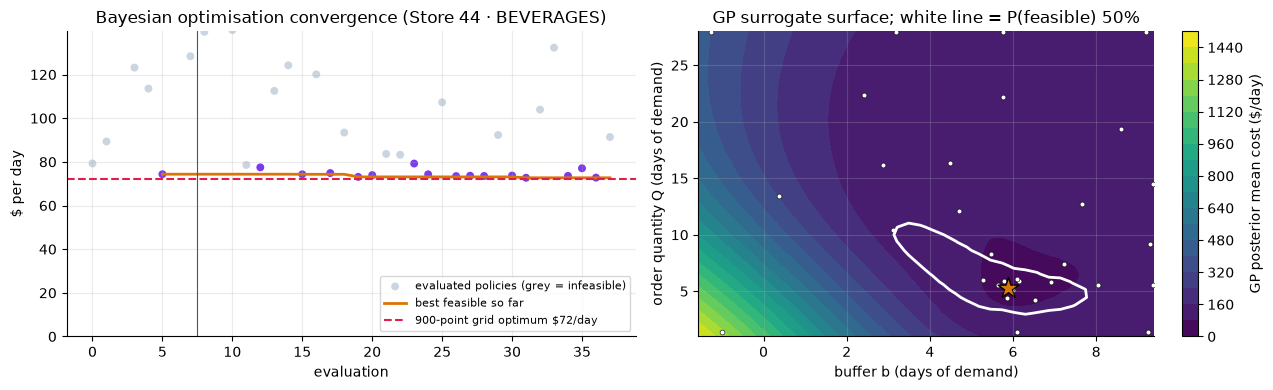

In [28]:
hist = pd.DataFrame(dd["history"])
grid_best = next(r for r in op["rows"] if r["series"] == dd["series"])["grid"]["cost"]
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].scatter(hist.index, hist.objective, c=np.where(hist.feasible, VIOLET, "#CBD5E1"), s=22, label="evaluated policies (grey = infeasible)")
axs[0].plot(hist.index, hist.bestObjective, color=AMBER, lw=2, label="best feasible so far")
axs[0].axhline(grid_best, color=RED, ls="--", label=f"900-point grid optimum ${grid_best:,.0f}/day")
axs[0].axvline(7.5, color=SLATE, lw=0.8); axs[0].set_xlabel("evaluation"); axs[0].set_ylabel("$ per day"); axs[0].legend(fontsize=8)
axs[0].set_title("Bayesian optimisation convergence (Store 44 · BEVERAGES)"); axs[0].set_ylim(0, np.nanpercentile(hist.objective, 90))
sf = dd["surface"]
D44 = next(r for r in op["rows"] if r["series"] == dd["series"])["meanDemand"]
X0, X1 = np.meshgrid(np.array(sf["x0"]) / D44, np.array(sf["x1"]) / D44)
cs = axs[1].contourf(X0, X1, np.array(sf["mean"]), levels=20, cmap="viridis")
axs[1].contour(X0, X1, np.array(sf["pFeasible"]), levels=[0.5], colors="white", linewidths=2)
axs[1].scatter(hist.x.str[0] / D44, hist.x.str[1] / D44, c="white", s=12, edgecolors="black", linewidths=0.4)
bx = dd["policies"]["bo"]; axs[1].scatter([bx["buffer"] / D44], [bx["orderQty"] / D44], marker="*", s=250, c=AMBER, edgecolors="black")
plt.colorbar(cs, ax=axs[1], label="GP posterior mean cost ($/day)")
axs[1].set_xlabel("buffer b (days of demand)"); axs[1].set_ylabel("order quantity Q (days of demand)")
axs[1].set_title("GP surrogate surface; white line = P(feasible) 50%"); plt.tight_layout(); plt.show()

In [29]:
print(f"• BO vs exhaustive grid: median gap {O['BO vs grid'].median():+.2%} (range {O['BO vs grid'].min():+.2%} to {O['BO vs grid'].max():+.2%}) "
      f"using 38 instead of 900 simulations ({38/900:.0%}).")
bev = O[O.index.str.contains("BEVERAGES")]
print(f"• Beverages (4 series): baseline ${bev['baseline $/day'].mean():,.0f}/day (fill {bev['baseline fill'].mean():.1%}, meets the 98% target in "
      f"{int(bev['baseline feasible'].sum())}/4) → optimised ${bev['BO $/day'].mean():,.0f}/day, all constraints met.")
slow = O[~O.index.str.contains("BEVERAGES|GROCERY")]
print(f"• Slow movers (Cleaning, Personal Care): EOQ = {slow['EOQ (days)'].min():.0f}–{slow['EOQ (days)'].max():.0f} days of demand → peak stock "
      f"breaks the 18-day storage capacity, so the classic policy is infeasible; BO finds the cheapest policy that fits "
      f"(Q ≈ {slow['BO Q (days)'].mean():.0f} days, peak ≈ {slow['BO peak (days)'].mean():.0f} days = capacity binding).")

• BO vs exhaustive grid: median gap -1.71% (range -3.46% to +0.59%) using 38 instead of 900 simulations (4%).
• Beverages (4 series): baseline $231/day (fill 96.9%, meets the 98% target in 0/4) → optimised $70/day, all constraints met.
• Slow movers (Cleaning, Personal Care): EOQ = 14–28 days of demand → peak stock breaks the 18-day storage capacity, so the classic policy is infeasible; BO finds the cheapest policy that fits (Q ≈ 9 days, peak ≈ 18 days = capacity binding).
